In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target
class_names = iris.target_names

print("Dataset shape:", X.shape)
print("Classes:", class_names)
print("Class distribution:", np.bincount(y))

# Split into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution:", np.bincount(y_test))

# Define models
models = {
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(
            max_depth=3, random_state=RANDOM_STATE
        ))
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE
        ))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ])
}

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Class distribution: [50 50 50]
Train: (120, 4)
Test: (30, 4)
Train class distribution: [40 40 40]
Test class distribution: [10 10 10]


In [2]:
results = []
predictions = {}
probabilities = {}

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    predictions[name] = y_pred
    probabilities[name] = y_proba

    # Calculate ROC-AUC for each class (One-vs-Rest)
    class_aucs = []

    for i in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        class_aucs.append(auc(fpr, tpr))

    macro_auc = np.mean(class_aucs)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1": f1_score(y_test, y_pred, average="macro"),
        "AUC": macro_auc
    })

    print(f"\n{'='*45}")
    print(f"Model: {name}")
    print(classification_report(
        y_test, y_pred,
        target_names=class_names,
        zero_division=0
    ))

# Summary table
results_df = pd.DataFrame(results)

print("\nSUMMARY TABLE")
display(results_df.round(4))


Model: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Model: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: KNN
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica 

,Model,Accuracy,Precision,Recall,F1,AUC
0,Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9717
1,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9967
2,KNN,0.9333,0.9444,0.9333,0.9327,0.9933


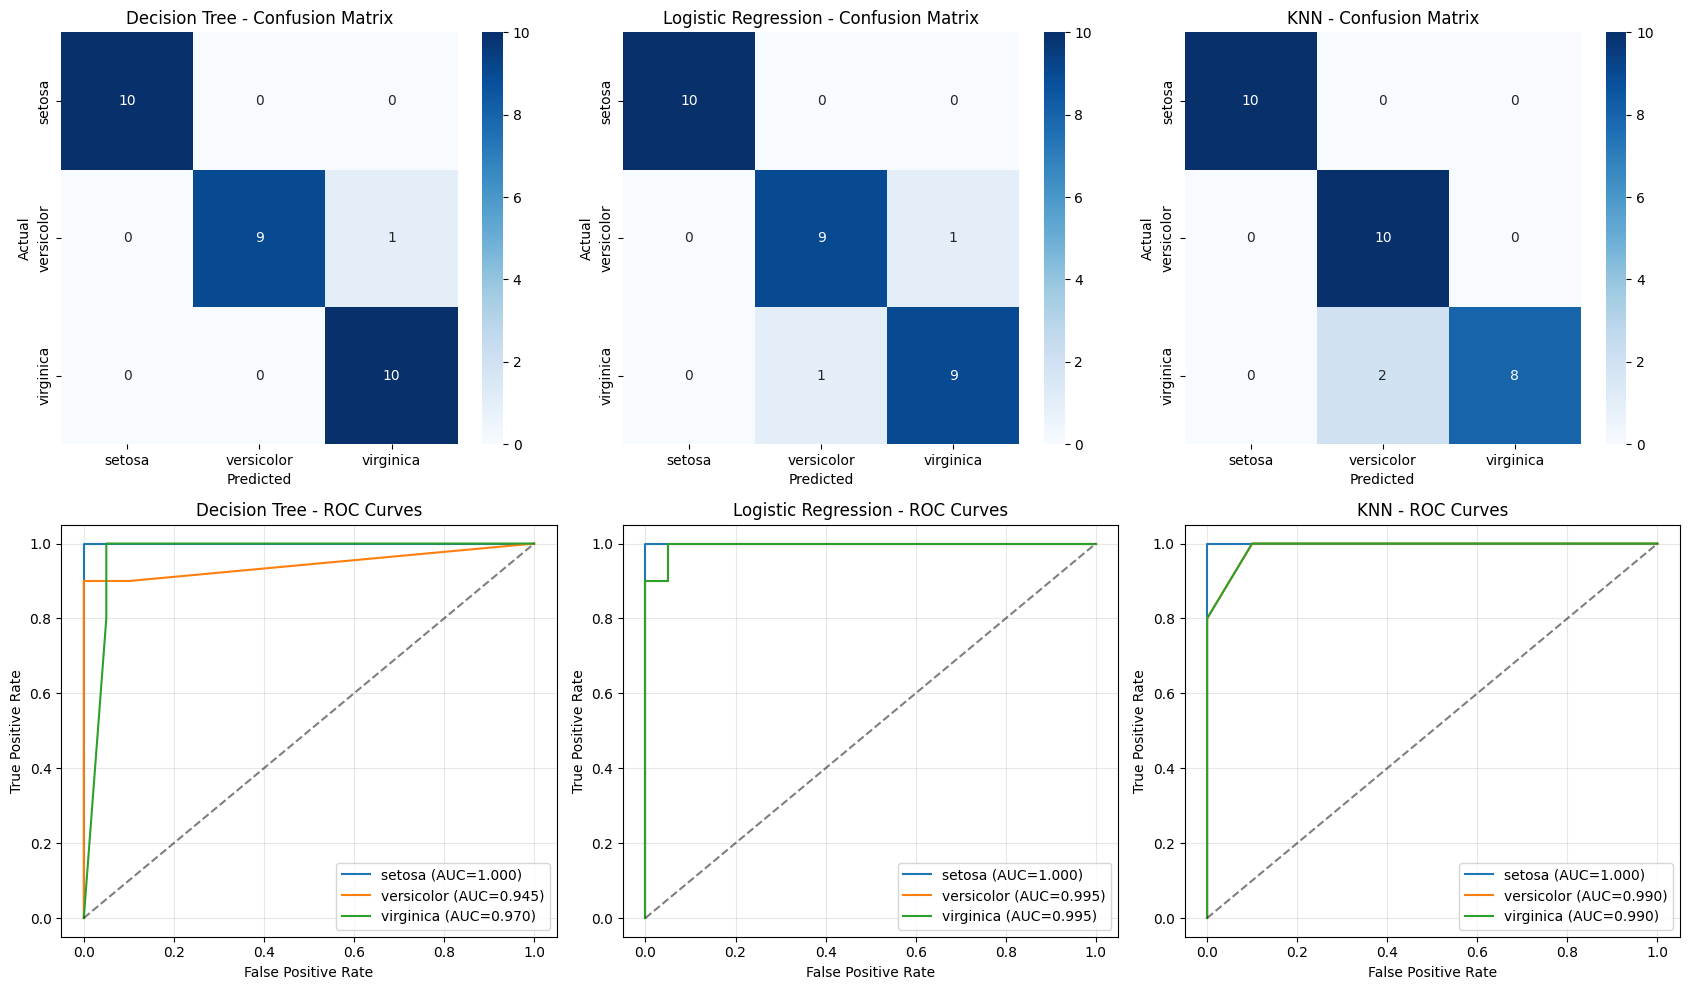

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for i, (name, model) in enumerate(models.items()):

    # Confusion Matrix
    cm = confusion_matrix(y_test, predictions[name])

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[0, i]
    )

    axes[0, i].set_title(f"{name} - Confusion Matrix")
    axes[0, i].set_xlabel("Predicted")
    axes[0, i].set_ylabel("Actual")

    # ROC Curves (One-vs-Rest)
    for j, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(
            y_test_bin[:, j],
            probabilities[name][:, j]
        )

        roc_auc = auc(fpr, tpr)

        axes[1, i].plot(
            fpr, tpr,
            label=f"{class_name} (AUC={roc_auc:.3f})"
        )

    axes[1, i].plot(
        [0, 1], [0, 1], "k--", alpha=0.5
    )

    axes[1, i].set_title(f"{name} - ROC Curves")
    axes[1, i].set_xlabel("False Positive Rate")
    axes[1, i].set_ylabel("True Positive Rate")
    axes[1, i].legend()
    axes[1, i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

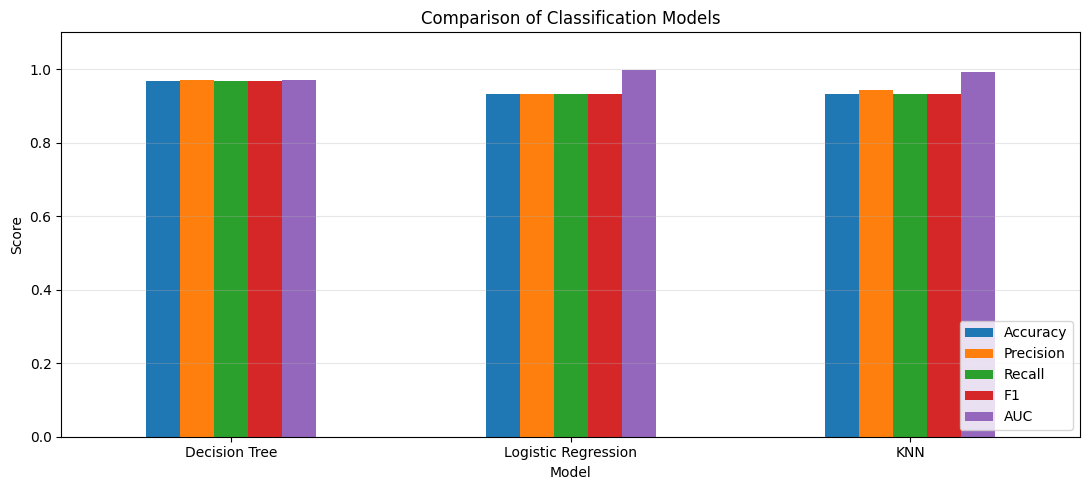

FINAL CONCLUSION
The best overall model is Decision Tree.
Accuracy: 0.9667
F1-score (macro): 0.9666
AUC (macro): 0.9717


In [4]:
# Compare model performance
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1.1),
    rot=0
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Determine best model using Accuracy, F1 and AUC
results_df["Overall Score"] = results_df[
    ["Accuracy", "F1", "AUC"]
].mean(axis=1)

best = results_df.sort_values(
    ["Overall Score", "F1", "AUC"],
    ascending=False
).iloc[0]

print("FINAL CONCLUSION")
print(f"The best overall model is {best['Model']}.")
print(f"Accuracy: {best['Accuracy']:.4f}")
print(f"F1-score (macro): {best['F1']:.4f}")
print(f"AUC (macro): {best['AUC']:.4f}")

### Task 1 — Conclusion

Three classification algorithms were evaluated on the Iris dataset: Decision Tree, Logistic Regression, and KNN. The dataset was divided into 80% training and 20% testing data. Decision Tree achieved the highest accuracy of 96.67% and an F1-score of 0.9666, correctly classifying 29 out of 30 samples. Logistic Regression and KNN both achieved 93.33% accuracy. All three models classified the Setosa class correctly, while most errors occurred between Versicolor and Virginica. Logistic Regression achieved a higher ROC-AUC despite having lower accuracy. Overall, Decision Tree demonstrated the best balance of classification accuracy and F1-score on this test set.

,Feature,Importance
2,petal length (cm),0.5791
3,petal width (cm),0.4209
1,sepal width (cm),0.0000
0,sepal length (cm),0.0000


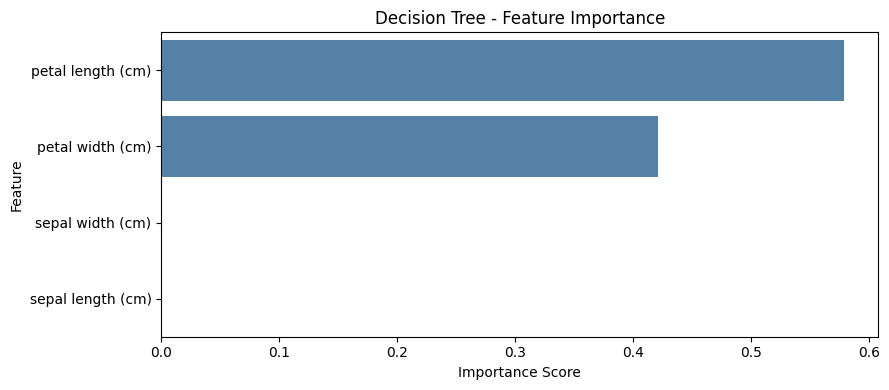

In [5]:
# Task 2.1 - Feature Importance

tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
tree.fit(X_train, y_train)

importance_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": tree.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 4))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Decision Tree - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

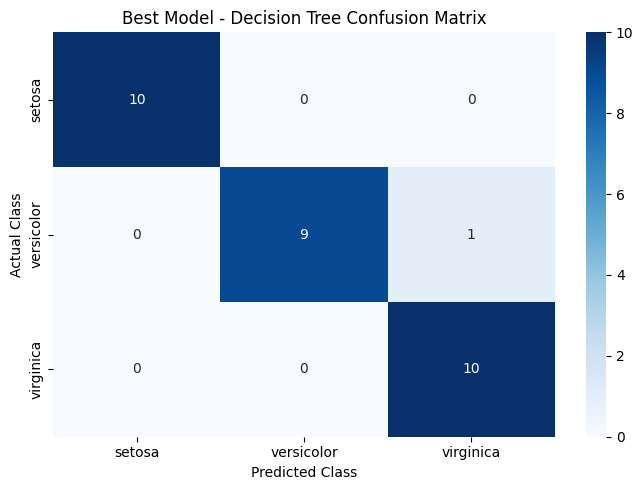

Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [6]:
# Task 2.2 - Confusion Matrix

best_model = models["Decision Tree"]
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Best Model - Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=class_names
))

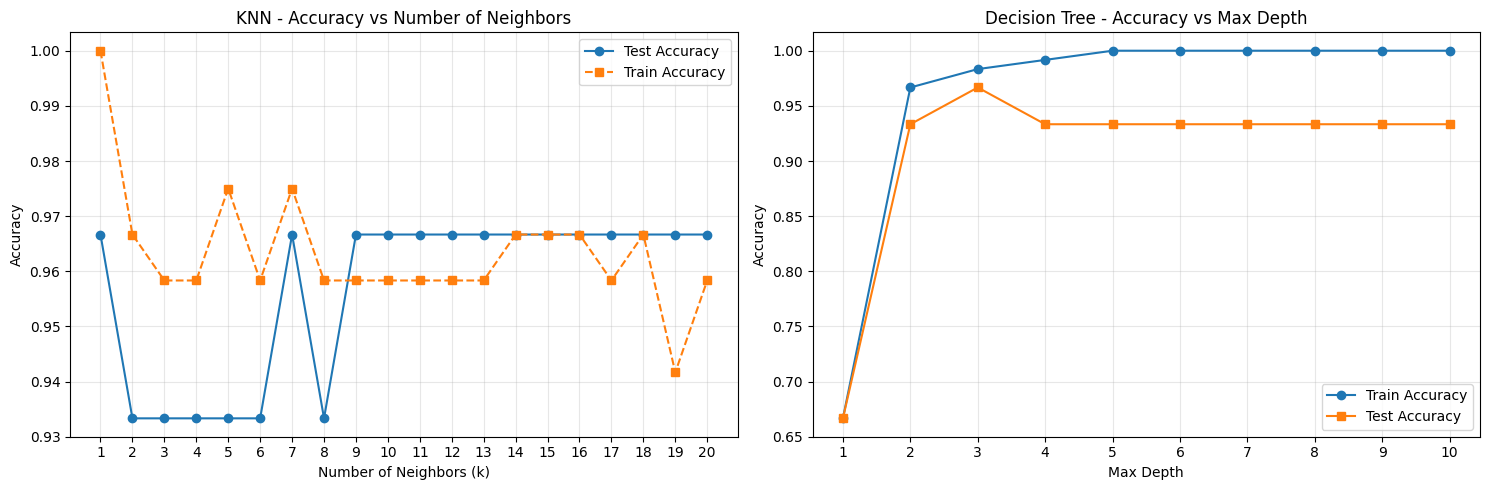

HYPERPARAMETER RESULTS
Best KNN k: 1
Best KNN Test Accuracy: 0.9667
Best Decision Tree depth: 3
Best Decision Tree Test Accuracy: 0.9667

Most important feature:
petal length (cm)


In [7]:
# Task 2.3 - Hyperparameter Experiments

# KNN: k = 1 to 20
knn_train_acc = []
knn_test_acc = []
k_values = range(1, 21)

for k in k_values:
    knn = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=k))
    ])

    knn.fit(X_train, y_train)

    knn_train_acc.append(knn.score(X_train, y_train))
    knn_test_acc.append(knn.score(X_test, y_test))

# Decision Tree: max_depth = 1 to 10
tree_train_acc = []
tree_test_acc = []
depth_values = range(1, 11)

for depth in depth_values:
    dt = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt.fit(X_train, y_train)

    tree_train_acc.append(dt.score(X_train, y_train))
    tree_test_acc.append(dt.score(X_test, y_test))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# KNN Accuracy
axes[0].plot(
    k_values, knn_test_acc,
    marker="o", label="Test Accuracy"
)
axes[0].plot(
    k_values, knn_train_acc,
    marker="s", linestyle="--", label="Train Accuracy"
)
axes[0].set_title("KNN - Accuracy vs Number of Neighbors")
axes[0].set_xlabel("Number of Neighbors (k)")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(list(k_values))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Decision Tree Accuracy
axes[1].plot(
    depth_values, tree_train_acc,
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    depth_values, tree_test_acc,
    marker="s", label="Test Accuracy"
)
axes[1].set_title("Decision Tree - Accuracy vs Max Depth")
axes[1].set_xlabel("Max Depth")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(list(depth_values))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Results
best_k = list(k_values)[np.argmax(knn_test_acc)]
best_depth = list(depth_values)[np.argmax(tree_test_acc)]

print("HYPERPARAMETER RESULTS")
print(f"Best KNN k: {best_k}")
print(f"Best KNN Test Accuracy: {max(knn_test_acc):.4f}")
print(f"Best Decision Tree depth: {best_depth}")
print(f"Best Decision Tree Test Accuracy: {max(tree_test_acc):.4f}")

print("\nMost important feature:")
print(importance_df.iloc[0]["Feature"])

### Task 2 — Conclusion

In this task, feature importance and hyperparameter tuning were analyzed using the Iris dataset. Petal length was the most important feature (57.91%), followed by petal width (42.09%). Sepal measurements were not used by the trained Decision Tree. The confusion matrix showed 96.67% accuracy, with only one misclassification between Versicolor and Virginica.

For KNN, the highest test accuracy of 96.67% was achieved at k=1, although this setting may increase the risk of overfitting. Accuracy was also relatively stable for larger values of k. For Decision Tree, the best maximum depth was 3, achieving 96.67% test accuracy. Increasing the depth beyond this point improved training accuracy but reduced test performance, indicating overfitting. Overall, petal measurements were the most useful features, and selecting appropriate hyperparameters helped achieve better generalization.

In [8]:
# Task 3.1 - Data Preparation

import torch
import torch.nn as nn
import copy
import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

config = {
    "hidden_dim": 32,
    "learning_rate": 0.01,
    "batch_size": 16,
    "epochs": 200,
    "weight_decay": 0.0001,
    "patience": 25
}

# Split: 60% train, 20% validation, 20% test
X_temp, X_test3, y_temp, y_test3 = train_test_split(
    X, y, test_size=0.2,
    stratify=y, random_state=SEED
)

X_train3, X_val3, y_train3, y_val3 = train_test_split(
    X_temp, y_temp, test_size=0.25,
    stratify=y_temp, random_state=SEED
)

scaler3 = StandardScaler()
X_train3 = scaler3.fit_transform(X_train3)
X_val3 = scaler3.transform(X_val3)
X_test3 = scaler3.transform(X_test3)

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

train_x, train_y = to_tensor(X_train3, y_train3)
val_x, val_y = to_tensor(X_val3, y_val3)
test_x, test_y = to_tensor(X_test3, y_test3)

print("Train:", len(train_y), np.bincount(y_train3))
print("Validation:", len(val_y), np.bincount(y_val3))
print("Test:", len(test_y), np.bincount(y_test3))
print("Configuration:", config)

Train: 90 [30 30 30]
Validation: 30 [10 10 10]
Test: 30 [10 10 10]
Configuration: {'hidden_dim': 32, 'learning_rate': 0.01, 'batch_size': 16, 'epochs': 200, 'weight_decay': 0.0001, 'patience': 25}


In [9]:
# Task 3.2 - Neural Network Training

class SimplePerceptron(nn.Module):
    def __init__(self, activation):
        super().__init__()

        activations = {
            "ReLU": nn.ReLU(),
            "Sigmoid": nn.Sigmoid(),
            "Tanh": nn.Tanh()
        }

        self.network = nn.Sequential(
            nn.Linear(4, config["hidden_dim"]),
            activations[activation],
            nn.Linear(config["hidden_dim"], 3)
        )

    def forward(self, x):
        return self.network(x)


def train_model(activation):
    # Same initial weights and random seed for fair comparison
    torch.manual_seed(SEED)

    model = SimplePerceptron(activation)
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"]
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_loss = float("inf")
    best_weights = None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()

        # Mini-batch training
        indices = torch.randperm(len(train_x))

        for start in range(0, len(train_x), config["batch_size"]):
            batch_idx = indices[start:start + config["batch_size"]]

            optimizer.zero_grad()
            output = model(train_x[batch_idx])
            loss = criterion(output, train_y[batch_idx])

            loss.backward()
            optimizer.step()

        # Evaluate train and validation
        model.eval()
        with torch.no_grad():
            train_output = model(train_x)
            val_output = model(val_x)

            train_loss = criterion(train_output, train_y).item()
            val_loss = criterion(val_output, val_y).item()

            train_acc = (
                train_output.argmax(1) == train_y
            ).float().mean().item()

            val_acc = (
                val_output.argmax(1) == val_y
            ).float().mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Early stopping
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= config["patience"]:
            break

    model.load_state_dict(best_weights)
    return model, history


trained_models = {}
histories = {}
results3 = []

for activation in ["ReLU", "Sigmoid", "Tanh"]:
    model, history = train_model(activation)

    trained_models[activation] = model
    histories[activation] = history

    model.eval()
    with torch.no_grad():
        predictions3 = model(test_x).argmax(1).numpy()

    results3.append({
        "Activation": activation,
        "Accuracy": accuracy_score(y_test3, predictions3),
        "Precision": precision_score(
            y_test3, predictions3, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test3, predictions3, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test3, predictions3, average="macro", zero_division=0
        ),
        "Epochs": len(history["train_loss"])
    })

    print(f"{activation}: Training completed "
          f"({len(history['train_loss'])} epochs)")

results3_df = pd.DataFrame(results3)
display(results3_df.round(4))

ReLU: Training completed (58 epochs)
Sigmoid: Training completed (57 epochs)
Tanh: Training completed (43 epochs)


,Activation,Accuracy,Precision,Recall,F1,Epochs
0,ReLU,0.9333,0.9333,0.9333,0.9333,58
1,Sigmoid,0.9333,0.9333,0.9333,0.9333,57
2,Tanh,0.9333,0.9333,0.9333,0.9333,43


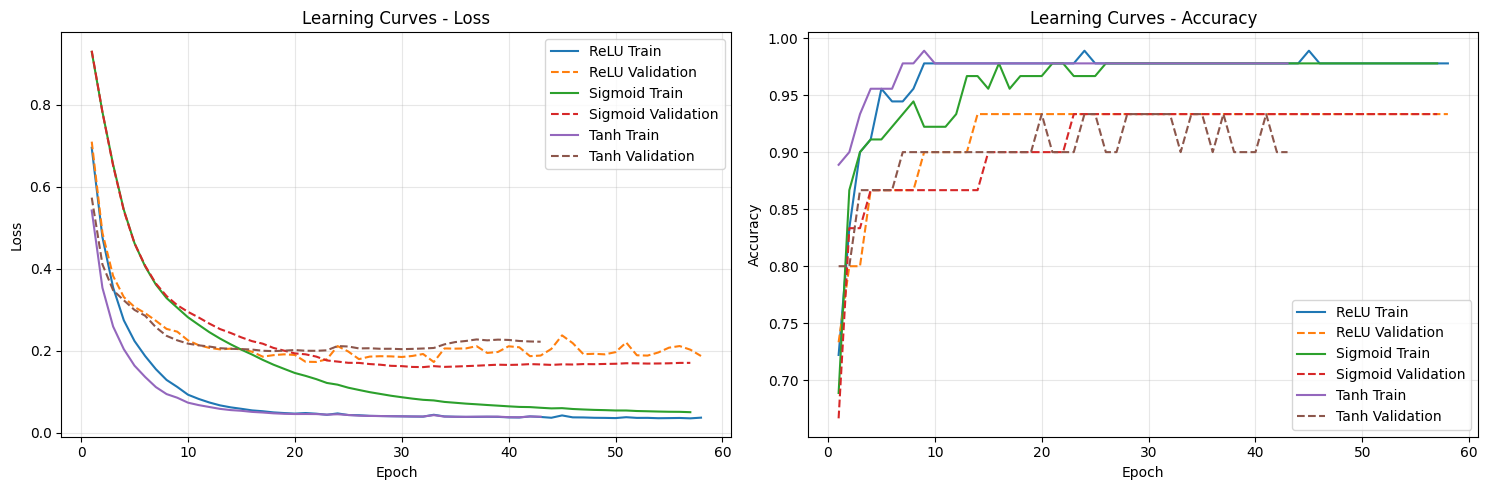

In [10]:
# Task 3.3 - Learning Curves

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for activation, history in histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs, history["train_loss"],
        label=f"{activation} Train"
    )
    axes[0].plot(
        epochs, history["val_loss"],
        linestyle="--",
        label=f"{activation} Validation"
    )

    axes[1].plot(
        epochs, history["train_acc"],
        label=f"{activation} Train"
    )
    axes[1].plot(
        epochs, history["val_acc"],
        linestyle="--",
        label=f"{activation} Validation"
    )

axes[0].set_title("Learning Curves - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Learning Curves - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

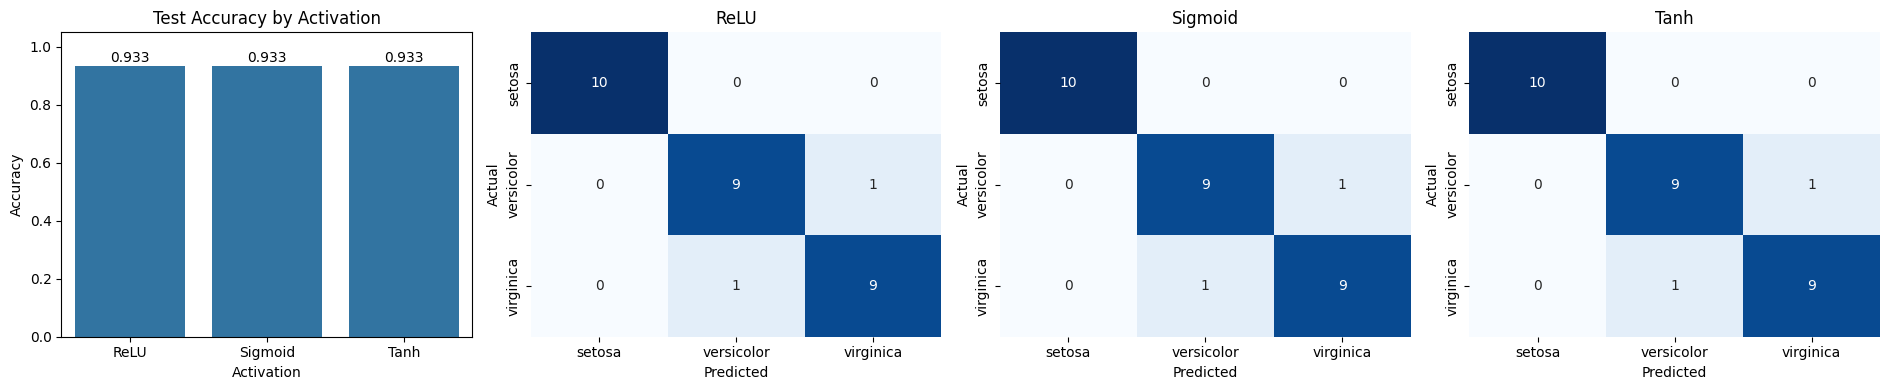

FINAL RESULTS


,Activation,Accuracy,Precision,Recall,F1,Epochs
0,ReLU,0.9333,0.9333,0.9333,0.9333,58
1,Sigmoid,0.9333,0.9333,0.9333,0.9333,57
2,Tanh,0.9333,0.9333,0.9333,0.9333,43



Best activation: ReLU
Test Accuracy: 0.9333
F1-score: 0.9333


In [11]:
# Task 3.4 - Final Evaluation

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# Accuracy bar chart
sns.barplot(
    data=results3_df,
    x="Activation",
    y="Accuracy",
    ax=axes[0]
)

axes[0].set_title("Test Accuracy by Activation")
axes[0].set_ylim(0, 1.05)

for i, row in results3_df.iterrows():
    axes[0].text(
        i, row["Accuracy"] + 0.015,
        f"{row['Accuracy']:.3f}",
        ha="center"
    )

# Confusion matrices
for i, (activation, model) in enumerate(trained_models.items()):
    model.eval()

    with torch.no_grad():
        y_pred3 = model(test_x).argmax(1).numpy()

    cm = confusion_matrix(y_test3, y_pred3)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i + 1],
        cbar=False
    )

    axes[i + 1].set_title(activation)
    axes[i + 1].set_xlabel("Predicted")
    axes[i + 1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Final results
best3 = results3_df.sort_values(
    ["Accuracy", "F1"], ascending=False
).iloc[0]

print("FINAL RESULTS")
display(results3_df.round(4))

print(f"\nBest activation: {best3['Activation']}")
print(f"Test Accuracy: {best3['Accuracy']:.4f}")
print(f"F1-score: {best3['F1']:.4f}")

# Save metrics as CSV
results3_df.to_csv("task3_metrics.csv", index=False)

### Task 3 — Conclusion

In this task, a simple neural network with one hidden layer was implemented using PyTorch to classify the Iris dataset. Three activation functions were compared: ReLU, Sigmoid, and Tanh. All models used the same architecture, optimizer, and training parameters.

All three activation functions achieved the same test accuracy of 93.33% and an F1-score of 0.9333, correctly classifying 28 out of 30 samples. However, their training behavior was different. Tanh showed the fastest initial reduction in training loss and stopped after 43 epochs, compared to 57 epochs for Sigmoid and 58 epochs for ReLU. The learning curves showed signs of overfitting, as validation loss stopped improving while training loss continued to decrease. Early stopping was used to prevent unnecessary training.

Overall, all three activation functions performed equally well on the test dataset. Tanh required fewer training epochs in this experiment, making it a reasonable choice for this small classification task. However, more experiments would be needed to determine whether this advantage is consistent.

In [12]:
# Task 4.1 - Data Preparation

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import copy

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# MNIST: pixel values normalized to [0, 1]
transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="./data", train=True,
    download=True, transform=transform
)

test_data = datasets.MNIST(
    root="./data", train=False,
    download=True, transform=transform
)

# 54,000 train / 6,000 validation / 10,000 test
train_data, val_data = random_split(
    train_full, [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(val_data, batch_size=512)
test_loader = DataLoader(test_data, batch_size=512)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

# Common configuration for all experiments
config4 = {
    "lr": 0.001,
    "weight_decay": 0.0001,
    "epochs": [5, 10, 20],
    "batch_sizes": [32, 64, 128]
}

Device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 31.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.25MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.75MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.80MB/s]

Train: 54000
Validation: 6000
Test: 10000


In [13]:
# Task 4.2 - MLP Training and Experiments

class MNIST_MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


criterion4 = nn.CrossEntropyLoss()

def evaluate4(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion4(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


# Identical starting weights for every experiment
torch.manual_seed(SEED)
initial_weights = copy.deepcopy(MNIST_MLP().state_dict())

results4 = []
histories4 = {}
trained_models4 = {}

for batch_size in config4["batch_sizes"]:
    for epochs in config4["epochs"]:

        torch.manual_seed(SEED)

        model = MNIST_MLP().to(device)
        model.load_state_dict(initial_weights)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=config4["lr"],
            weight_decay=config4["weight_decay"]
        )

        train_loader = DataLoader(
            train_data,
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(SEED)
        )

        history = {
            "train_loss": [], "val_loss": [],
            "train_acc": [], "val_acc": []
        }

        start_time = time.time()

        for epoch in range(epochs):
            model.train()
            running_loss = 0
            correct, total = 0, 0

            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)
                loss = criterion4(outputs, labels)

                loss.backward()
                optimizer.step()

                running_loss += loss.item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

            train_loss = running_loss / total
            train_acc = correct / total

            val_loss, val_acc = evaluate4(model, val_loader)

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

        training_time = time.time() - start_time

        # Save the final model for this configuration
        key = (epochs, batch_size)
        trained_models4[key] = copy.deepcopy(
            model.cpu().state_dict()
        )
        histories4[key] = history

        results4.append({
            "Epochs": epochs,
            "Batch Size": batch_size,
            "Train Accuracy": train_acc,
            "Val Accuracy": val_acc,
            "Train Loss": train_loss,
            "Val Loss": val_loss,
            "Time (s)": training_time
        })

        print(
            f"Epochs={epochs}, Batch={batch_size} | "
            f"Val Accuracy={val_acc:.4f} | "
            f"Val Loss={val_loss:.4f} | "
            f"Time={training_time:.1f}s"
        )

results4_df = pd.DataFrame(results4)
display(results4_df.round(4))

Epochs=5, Batch=32 | Val Accuracy=0.9710 | Val Loss=0.1055 | Time=134.1s
Epochs=10, Batch=32 | Val Accuracy=0.9772 | Val Loss=0.0873 | Time=230.8s
Epochs=20, Batch=32 | Val Accuracy=0.9718 | Val Loss=0.1063 | Time=517.3s
Epochs=5, Batch=64 | Val Accuracy=0.9745 | Val Loss=0.0914 | Time=75.5s
Epochs=10, Batch=64 | Val Accuracy=0.9770 | Val Loss=0.0806 | Time=162.8s
Epochs=20, Batch=64 | Val Accuracy=0.9772 | Val Loss=0.0866 | Time=358.8s
Epochs=5, Batch=128 | Val Accuracy=0.9707 | Val Loss=0.0990 | Time=51.1s
Epochs=10, Batch=128 | Val Accuracy=0.9687 | Val Loss=0.1093 | Time=118.9s
Epochs=20, Batch=128 | Val Accuracy=0.9735 | Val Loss=0.1076 | Time=247.6s


,Epochs,Batch Size,Train Accuracy,Val Accuracy,Train Loss,Val Loss,Time (s)
0,5,32,0.9838,0.9710,0.0509,0.1055,134.1312
1,10,32,0.9898,0.9772,0.0306,0.0873,230.8156
2,20,32,0.9927,0.9718,0.0218,0.1063,517.2988
3,5,64,0.9834,0.9745,0.0518,0.0914,75.4687
4,10,64,0.9917,0.9770,0.0259,0.0806,162.7836
5,20,64,0.9953,0.9772,0.0137,0.0866,358.8291
6,5,128,0.9808,0.9707,0.0634,0.0990,51.1438
7,10,128,0.9925,0.9687,0.0242,0.1093,118.8700
8,20,128,0.9954,0.9735,0.0138,0.1076,247.5880


VALIDATION ACCURACY


Batch Size,32,64,128
Epochs,,,
5,0.9710,0.9745,0.9707
10,0.9772,0.9770,0.9687
20,0.9718,0.9772,0.9735


VALIDATION LOSS


Batch Size,32,64,128
Epochs,,,
5,0.1055,0.0914,0.0990
10,0.0873,0.0806,0.1093
20,0.1063,0.0866,0.1076


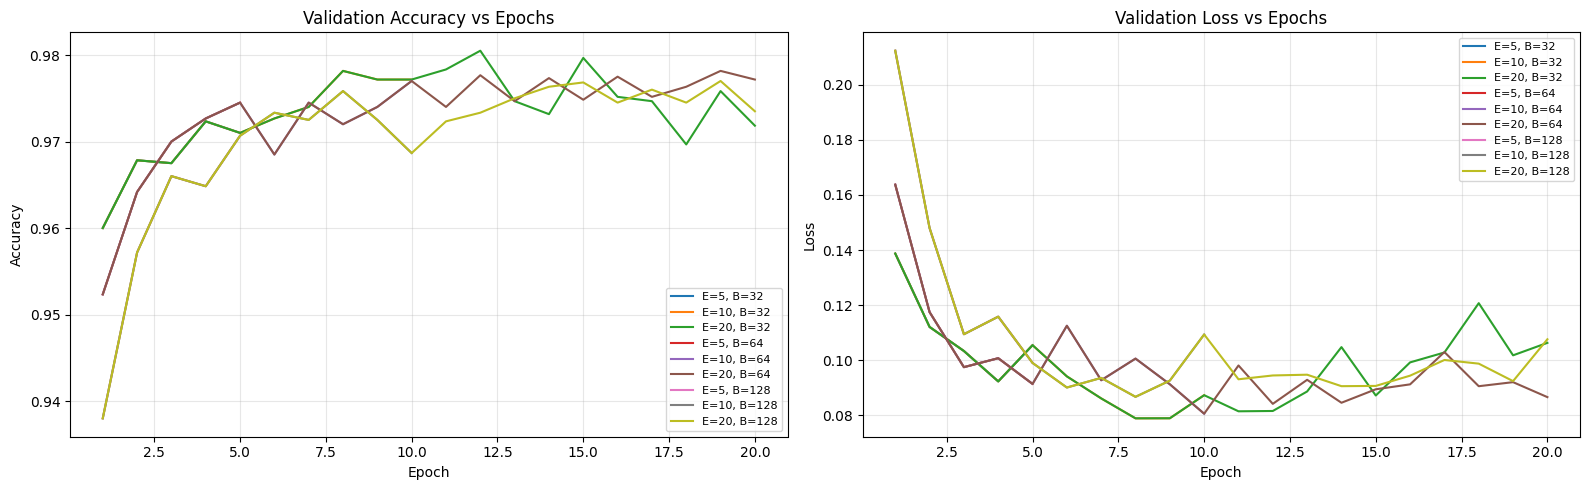

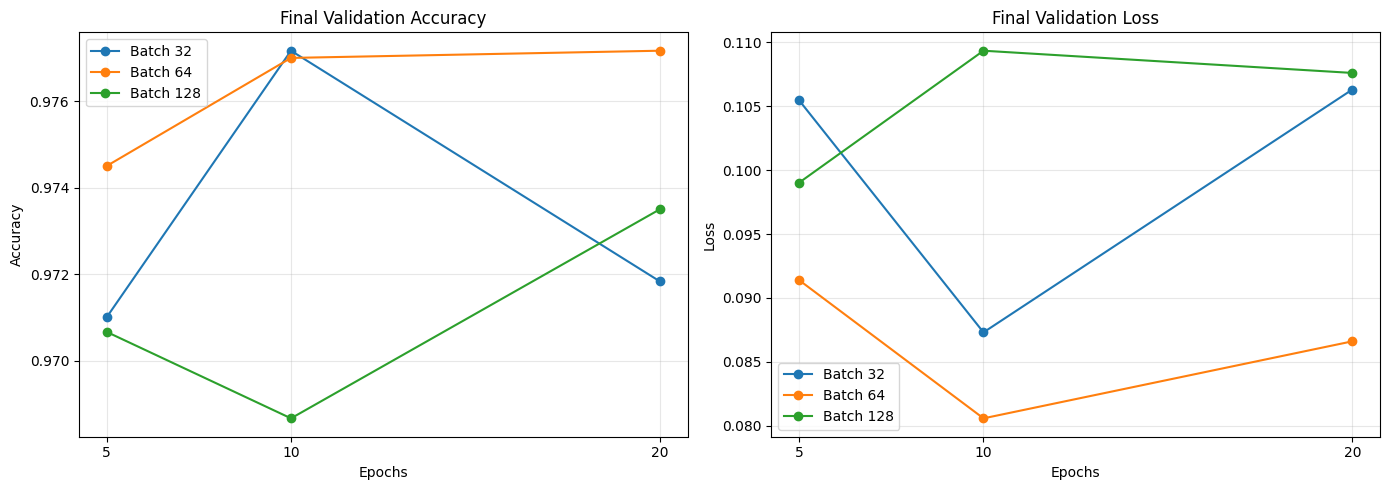

In [14]:
# Task 4.3 - Results and Learning Curves

print("VALIDATION ACCURACY")
display(
    results4_df.pivot(
        index="Epochs",
        columns="Batch Size",
        values="Val Accuracy"
    ).round(4)
)

print("VALIDATION LOSS")
display(
    results4_df.pivot(
        index="Epochs",
        columns="Batch Size",
        values="Val Loss"
    ).round(4)
)

# Learning curves for all 9 experiments
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for (epochs, batch), history in histories4.items():
    x = range(1, epochs + 1)
    label = f"E={epochs}, B={batch}"

    axes[0].plot(x, history["val_acc"], label=label)
    axes[1].plot(x, history["val_loss"], label=label)

axes[0].set_title("Validation Accuracy vs Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title("Validation Loss vs Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Accuracy and Loss by batch size and epochs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for batch in config4["batch_sizes"]:
    subset = results4_df[
        results4_df["Batch Size"] == batch
    ].sort_values("Epochs")

    axes[0].plot(
        subset["Epochs"], subset["Val Accuracy"],
        marker="o", label=f"Batch {batch}"
    )
    axes[1].plot(
        subset["Epochs"], subset["Val Loss"],
        marker="o", label=f"Batch {batch}"
    )

axes[0].set_title("Final Validation Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("Final Validation Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xticks([5, 10, 20])

plt.tight_layout()
plt.show()

BEST CONFIGURATION
Epochs: 20
Batch Size: 64
Validation Accuracy: 0.9772
Test Accuracy: 0.9781
Test Loss: 0.0837


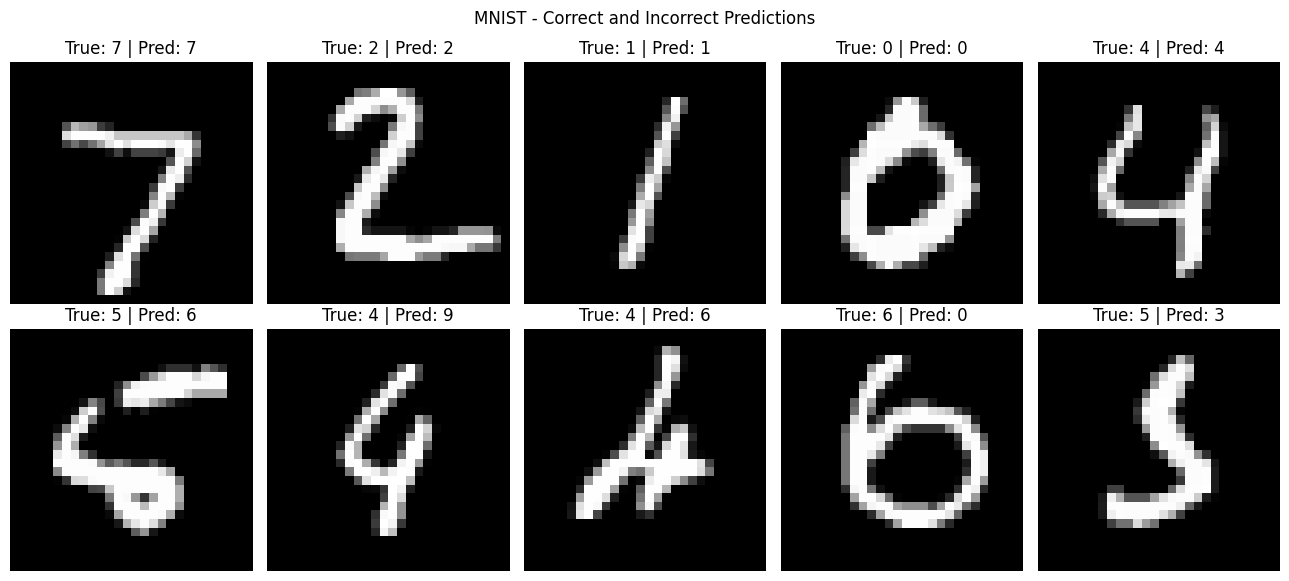

In [15]:
# Task 4.4 - Best Model and Predictions

best4 = results4_df.sort_values(
    ["Val Accuracy", "Val Loss"],
    ascending=[False, True]
).iloc[0]

best_key = (
    int(best4["Epochs"]),
    int(best4["Batch Size"])
)

best_model4 = MNIST_MLP().to(device)
best_model4.load_state_dict(trained_models4[best_key])
best_model4.eval()

test_loss, test_acc = evaluate4(best_model4, test_loader)

print("BEST CONFIGURATION")
print(f"Epochs: {best_key[0]}")
print(f"Batch Size: {best_key[1]}")
print(f"Validation Accuracy: {best4['Val Accuracy']:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Collect correct and incorrect examples
correct_examples = []
incorrect_examples = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = best_model4(images.to(device))
        preds = outputs.argmax(1).cpu()

        for image, true, pred in zip(images, labels, preds):
            item = (image.squeeze().numpy(), true.item(), pred.item())

            if true == pred and len(correct_examples) < 5:
                correct_examples.append(item)
            elif true != pred and len(incorrect_examples) < 5:
                incorrect_examples.append(item)

        if len(correct_examples) == 5 and len(incorrect_examples) == 5:
            break

# Visualize 5 correct and 5 incorrect predictions
fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i, (image, true, pred) in enumerate(correct_examples):
    axes[0, i].imshow(image, cmap="gray")
    axes[0, i].set_title(f"True: {true} | Pred: {pred}")
    axes[0, i].axis("off")

for i, (image, true, pred) in enumerate(incorrect_examples):
    axes[1, i].imshow(image, cmap="gray")
    axes[1, i].set_title(f"True: {true} | Pred: {pred}")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Correct", fontsize=12)
axes[1, 0].set_ylabel("Incorrect", fontsize=12)

plt.suptitle("MNIST - Correct and Incorrect Predictions")
plt.tight_layout()
plt.show()

# Save results
results4_df.to_csv("task4_results.csv", index=False)

### Task 4 — Conclusion

In this task, a Multilayer Perceptron (MLP) was implemented using PyTorch to classify handwritten digits from the MNIST dataset. The neural network contained three hidden layers with 256, 128, and 64 neurons, using ReLU activation and the Adam optimizer.

Nine experiments were conducted with different numbers of epochs (5, 10, 20) and batch sizes (32, 64, 128). The best configuration selected by validation accuracy was 10 epochs with a batch size of 32, achieving 97.72% validation accuracy and 97.81% test accuracy.

The results showed that increasing the number of epochs generally improved performance during early training. However, training for 20 epochs did not always improve validation accuracy and sometimes increased validation loss, indicating overfitting. Smaller batch sizes generally achieved competitive accuracy but required more training time. A batch size of 64 with 10 epochs offered a particularly good balance between accuracy, validation loss, and computational efficiency.

The visualization of predictions showed that most handwritten digits were classified correctly, while some errors occurred between visually similar digits, such as 4 and 9 or 6 and 0.

Overall, the experiments demonstrated that appropriate epoch and batch size selection is important for achieving high classification accuracy while avoiding unnecessary training time and overfitting.